In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

plt.rcParams["figure.figsize"] = (12, 4)
DATA_PATH = "Data/Energy Production Dataset.csv"

# 01. Data Exploration

## 1.1 Load and understand the data

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (51864, 9)


,Date,Start_Hour,End_Hour,Source,Day_of_Year,Day_Name,Month_Name,Season,Production
0,11/30/2025,21,22,Wind,334,Sunday,November,Fall,5281
1,11/30/2025,18,19,Wind,334,Sunday,November,Fall,3824
2,11/30/2025,16,17,Wind,334,Sunday,November,Fall,3824
3,11/30/2025,23,0,Wind,334,Sunday,November,Fall,6120
4,11/30/2025,6,7,Wind,334,Sunday,November,Fall,4387


In [3]:
df_raw.tail()

,Date,Start_Hour,End_Hour,Source,Day_of_Year,Day_Name,Month_Name,Season,Production
51859,1/1/2020,4,5,Wind,1,Wednesday,January,Winter,2708
51860,1/1/2020,18,19,Wind,1,Wednesday,January,Winter,1077
51861,1/1/2020,7,8,Wind,1,Wednesday,January,Winter,2077
51862,1/1/2020,14,15,Solar,1,Wednesday,January,Winter,1783
51863,1/1/2020,13,14,Solar,1,Wednesday,January,Winter,2179


In [4]:
df_raw.dtypes

Date           object
Start_Hour      int64
End_Hour        int64
Source         object
Day_of_Year     int64
Day_Name       object
Month_Name     object
Season         object
Production      int64
dtype: object

### Column description and units

| # | Column Name | Type | Range | Description |
|---|---|---|---|---|
| 1 | **Date** | String | 2020-01-01 to 2025-11-30 | Measurement date (stored as MM/DD/YYYY in the CSV) |
| 2 | **Start_Hour** | Integer | 0-23 | Starting hour of measurement period |
| 3 | **End_Hour** | Integer | 0-23 | Ending hour of measurement period |
| 4 | **Source** | Categorical | Wind, Solar, Mixed | Primary energy source (based on production dominance) |
| 5 | **Day_of_Year** | Integer | 1-366 | Day number within the year (cyclical temporal feature) |
| 6 | **Day_Name** | Categorical | Mon-Sun | Day of week (Monday through Sunday) |
| 7 | **Month_Name** | Categorical | Jan-Dec | Calendar month (January through December) |
| 8 | **Season** | Categorical | Winter, Spring, Summer, Fall | Meteorological season classification |
| 9 | **Production** | Integer | 58-23,446 MWh | Total renewable energy production |

- Time columns: `Date` + `Start_Hour` (one row per hour).
- Data origin: hourly wind and solar production in France (Open Data Réseaux Énergies), originally two columns
  `prod_eolienne_MWh` (wind) and `prod_solaire_MWh` (solar), aggregated by the Kaggle author.
- Target candidate: `Production` (MWh) – total renewable production of all sources in that hour.
- `Source` is only a label of the dominant source; it does not split `Production` by source.
- `Day_of_Year`, `Day_Name`, `Month_Name`, `Season` are all derived from `Date`.

## 1.2 Time checks

In [5]:
df = df_raw.copy()
df["timestamp"] = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce") \
                  + pd.to_timedelta(df["Start_Hour"], unit="h")
print("Parse errors (NaT):", df["timestamp"].isna().sum())

Parse errors (NaT): 0


In [6]:
df["timestamp"].sort_values().diff().value_counts()

timestamp
0 days 01:00:00    51851
0 days 02:00:00        6
0 days 00:00:00        6
Name: count, dtype: int64

In [7]:
full_range = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
missing_hours = full_range.difference(df["timestamp"])
duplicated_ts = df[df["timestamp"].duplicated(keep=False)].sort_values("timestamp")

print("From:", df["timestamp"].min(), " To:", df["timestamp"].max())
print("Days covered:", df["timestamp"].dt.normalize().nunique())
print("Expected hours:", len(full_range), " Unique timestamps:", df["timestamp"].nunique())
print("Missing hours:", list(missing_hours.strftime("%Y-%m-%d %H:%M")))
duplicated_ts[["timestamp", "Source", "Production"]]

From: 2020-01-01 00:00:00  To: 2025-11-30 23:00:00
Days covered: 2161
Expected hours: 51864  Unique timestamps: 51858
Missing hours: ['2020-03-29 02:00', '2021-03-28 02:00', '2022-03-27 02:00', '2023-03-26 02:00', '2024-03-31 02:00', '2025-03-30 02:00']


,timestamp,Source,Production
44698,2020-10-25 02:00:00,Wind,11001
44707,2020-10-25 02:00:00,Wind,10696
35784,2021-10-31 02:00:00,Wind,4784
35795,2021-10-31 02:00:00,Wind,4462
27057,2022-10-30 02:00:00,Wind,3262
27063,2022-10-30 02:00:00,Wind,3107
18321,2023-10-29 02:00:00,Wind,15488
18328,2023-10-29 02:00:00,Wind,15218
9577,2024-10-27 02:00:00,Wind,1876
9581,2024-10-27 02:00:00,Wind,1601


- The data is **hourly**.
- 6 missing hours (02:00 on the last Sunday of March) and 6 duplicated hours (02:00 on the last Sunday of October)
  are caused by **Daylight Saving Time** changes. The duplicated rows have different values, so they are two real hours, not copy errors.

## 1.3 Data quality checks

In [8]:
print("Missing values per column:")
print(df_raw.isna().sum())
print("\nFully duplicated rows:", df_raw.duplicated().sum())

Missing values per column:
Date           0
Start_Hour     0
End_Hour       0
Source         0
Day_of_Year    0
Day_Name       0
Month_Name     0
Season         0
Production     0
dtype: int64

Fully duplicated rows: 0


## 1.4 Source analysis

In [9]:
df["Source"].value_counts()

Source
Wind     42484
Solar     9378
Mixed        2
Name: count, dtype: int64

In [10]:
df.groupby("Source").agg(
    rows=("Production", "size"),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
    mean_production=("Production", "mean"),
    first_hour=("Start_Hour", "min"),
    last_hour=("Start_Hour", "max"),
)

,rows,first,last,mean_production,first_hour,last_hour
Source,,,,,,
Mixed,2,2020-04-08 19:00:00,2022-06-15 19:00:00,1737.000000,19,19
Solar,9378,2020-01-01 12:00:00,2025-11-26 14:00:00,5793.845703,7,20
Wind,42484,2020-01-01 00:00:00,2025-11-30 23:00:00,6308.262593,0,23


In [11]:
print("Number of sources per timestamp:")
df.groupby("timestamp")["Source"].nunique().value_counts()

Number of sources per timestamp:


Source
1    51858
Name: count, dtype: int64

**Target series decision**
- Each timestamp has exactly **one** row: `Production` is the total output of all sources, and `Source` only tells which source dominated that hour.
- Wind covers all hours, Solar only daytime (7h–20h), Mixed has just 2 rows. Filtering by source would create series with gaps.
- → Use the full hourly `Production` series as the target. `Source` is not used as a feature: it adds little beyond the hour of day
  (Solar only appears in daytime) and has very weak correlation with `Production`.

## 1.5 EDA

In [12]:
series = df.groupby("timestamp")["Production"].mean().sort_index()
series.describe()

count    51858.000000
mean      6214.905916
std       3978.226997
min         58.000000
25%       3111.000000
50%       5372.000000
75%       8500.000000
max      23446.000000
Name: Production, dtype: float64

In [13]:
series

timestamp
2020-01-01 00:00:00    3542.0
2020-01-01 01:00:00    2932.0
2020-01-01 02:00:00    2725.0
2020-01-01 03:00:00    2761.0
2020-01-01 04:00:00    2708.0
                        ...  
2025-11-30 19:00:00    4186.0
2025-11-30 20:00:00    4614.0
2025-11-30 21:00:00    5281.0
2025-11-30 22:00:00    5664.0
2025-11-30 23:00:00    6120.0
Name: Production, Length: 51858, dtype: float64

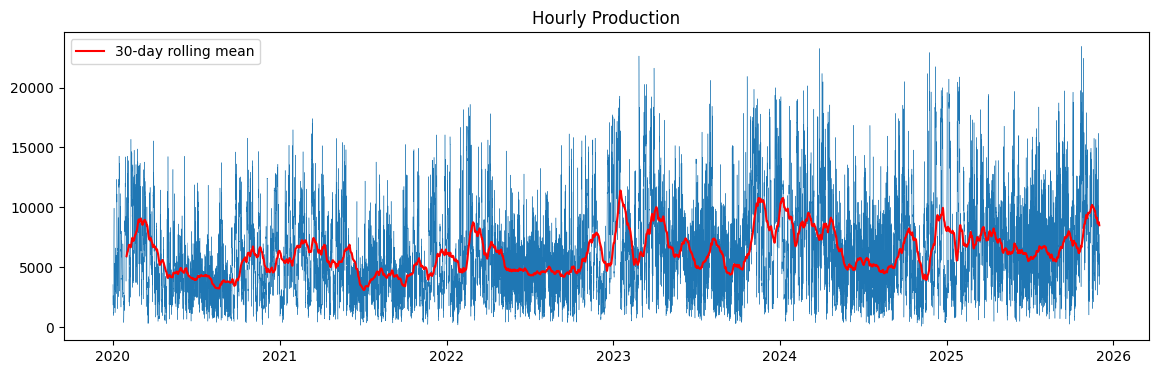

In [14]:
plt.figure(figsize=(14, 4))
plt.plot(series, linewidth=0.3)
plt.plot(series.rolling(24 * 30).mean(), color="red", label="30-day rolling mean")
plt.title("Hourly Production")
plt.legend()
plt.show()

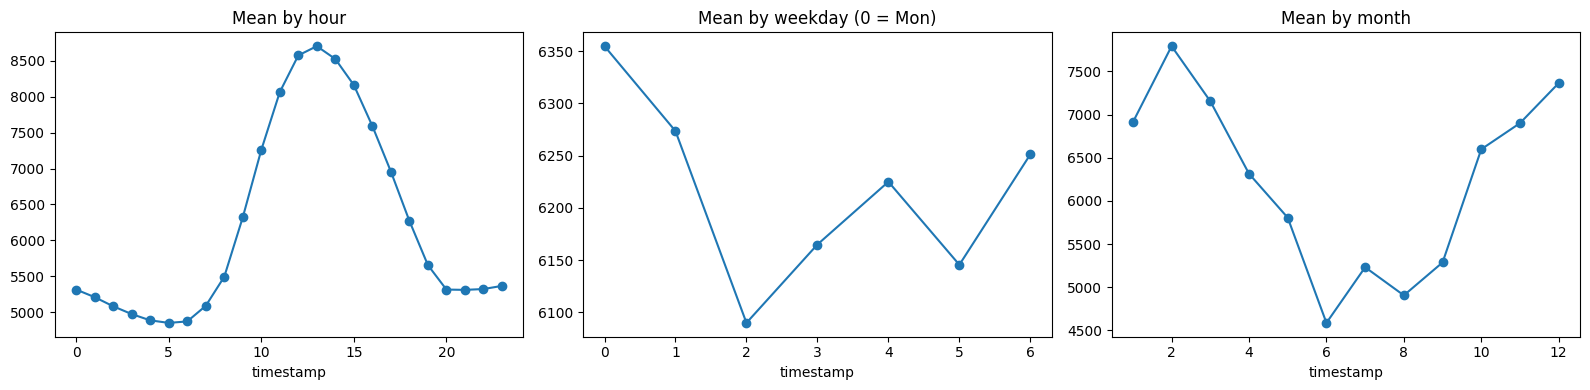

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
series.groupby(series.index.hour).mean().plot(ax=axes[0], marker="o", title="Mean by hour")
series.groupby(series.index.dayofweek).mean().plot(ax=axes[1], marker="o", title="Mean by weekday (0 = Mon)")
series.groupby(series.index.month).mean().plot(ax=axes[2], marker="o", title="Mean by month")
plt.tight_layout()
plt.show()

- Clear **daily cycle** (higher during daytime because of solar) and **yearly cycle** (higher in winter because of wind).
- No weekly pattern.

In [16]:
lags = [1, 2, 3, 6, 12, 24, 48, 168]
pd.Series({lag: round(series.autocorr(lag), 3) for lag in lags}, name="autocorrelation")

1      0.981
2      0.938
3      0.884
6      0.716
12     0.528
24     0.595
48     0.417
168    0.261
Name: autocorrelation, dtype: float64

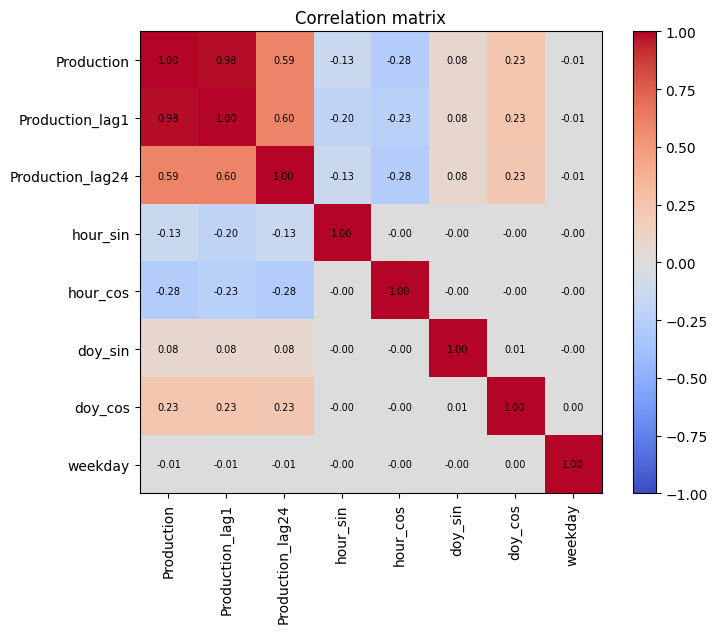

In [17]:
corr_df = pd.DataFrame({
    "Production": series,
    "Production_lag1": series.shift(1),
    "Production_lag24": series.shift(24),
    "hour_sin": np.sin(2 * np.pi * series.index.hour / 24),
    "hour_cos": np.cos(2 * np.pi * series.index.hour / 24),
    "doy_sin": np.sin(2 * np.pi * series.index.dayofyear / 365.25),
    "doy_cos": np.cos(2 * np.pi * series.index.dayofyear / 365.25),
    "weekday": series.index.dayofweek,
})
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
plt.title("Correlation matrix")
plt.show()

- Past values (`lag1`, `lag24`) are the strongest predictors.
- `hour_cos` and `doy_cos` capture the daily and yearly cycles.
- `weekday` has almost no correlation and are not used.

# 02. Problem Definition

In [18]:
PRED_COLUMN = "Production"
FEATURE_COLUMNS = ["Production", "hour_sin", "hour_cos", "doy_sin", "doy_cos"]
LOOKBACK = 24
HORIZON = 5

| Item | Decision |
|---|---|
| Target (`pred_column`) | `Production` (MWh), the measured hourly energy output |
| Input features | Past `Production`, hour of day and day of year (sin/cos) – 5 features |
| Lookback | 24 hours – autocorrelation is highest for recent hours and peaks again at lag 24 (daily cycle) |
| Output | `Production` at t+1 … t+5 |
| Problem type | Multivariate input → univariate multi-step output (seq2seq) |

Future values of `Production` are unknown, so only past values are used as input.

```
Encoder input: [t-23, ..., t]  (24, 5)   ──►   Decoder output: [t+1, t+2, t+3, t+4, t+5]  (5, 1)
```

# 03. Preprocessing

## 3.1 Cleaning
- Sort by time.
- Daylight Saving Time: the duplicated 02:00 in October is merged by averaging, the missing 02:00 in March is filled by linear interpolation.
- Outliers are kept (real high-wind hours).

In [19]:
data = df.sort_values("timestamp").groupby("timestamp")[["Production"]].mean()
data = data.asfreq("h")
data["Production"] = data["Production"].interpolate()

print("Rows:", len(data))
print("Duplicated timestamps:", data.index.duplicated().sum())
print("Missing values:", data.isna().sum().sum())

Rows: 51864
Duplicated timestamps: 0
Missing values: 0


## 3.2 Feature engineering
Hour and day of year are cyclical (23h is next to 0h, 31 Dec is next to 1 Jan), so they are encoded with sin/cos.

In [20]:
data["hour_sin"] = np.sin(2 * np.pi * data.index.hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * data.index.hour / 24)
data["doy_sin"] = np.sin(2 * np.pi * data.index.dayofyear / 365.25)
data["doy_cos"] = np.cos(2 * np.pi * data.index.dayofyear / 365.25)

data[FEATURE_COLUMNS].head()

,Production,hour_sin,hour_cos,doy_sin,doy_cos
timestamp,,,,,
2020-01-01 00:00:00,3542.0,0.000000,1.000000,0.017202,0.999852
2020-01-01 01:00:00,2932.0,0.258819,0.965926,0.017202,0.999852
2020-01-01 02:00:00,2725.0,0.500000,0.866025,0.017202,0.999852
2020-01-01 03:00:00,2761.0,0.707107,0.707107,0.017202,0.999852
2020-01-01 04:00:00,2708.0,0.866025,0.500000,0.017202,0.999852


## 3.3 Train / validation / test split
Chronological split 70% / 15% / 15%, no shuffling.

In [21]:
n = len(data)
train_df = data.iloc[:int(n * 0.70)]
val_df = data.iloc[int(n * 0.70):int(n * 0.85)]
test_df = data.iloc[int(n * 0.85):]

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11} {part.index.min()} -> {part.index.max()}  ({len(part)} rows)")

print("\nNo leakage:", train_df.index.max() < val_df.index.min() and val_df.index.max() < test_df.index.min())

train       2020-01-01 00:00:00 -> 2024-02-21 15:00:00  (36304 rows)
validation  2024-02-21 16:00:00 -> 2025-01-10 19:00:00  (7780 rows)
test        2025-01-10 20:00:00 -> 2025-11-30 23:00:00  (7780 rows)

No leakage: True


## 3.4 Scaling
`MinMaxScaler` is fit on the training set only, then applied to validation and test.

In [22]:
scaler = MinMaxScaler().fit(train_df[FEATURE_COLUMNS])


def scale(part):
    return pd.DataFrame(scaler.transform(part[FEATURE_COLUMNS]), index=part.index, columns=FEATURE_COLUMNS)


train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)

train_scaled.describe().loc[["min", "max"]]

,Production,hour_sin,hour_cos,doy_sin,doy_cos
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


## 3.5 Save processed data
The scaled splits are saved to 3 CSV files. Each file also keeps the original `Production_MWh` column (not scaled),
which is used in `task2_model.py` to convert predictions back to MWh.

In [23]:
train_scaled["Production_MWh"] = train_df["Production"]
val_scaled["Production_MWh"] = val_df["Production"]
test_scaled["Production_MWh"] = test_df["Production"]

train_scaled.to_csv("Data/train.csv", index_label="timestamp")
val_scaled.to_csv("Data/validation.csv", index_label="timestamp")
test_scaled.to_csv("Data/test.csv", index_label="timestamp")
train_scaled.head()

,Production,hour_sin,hour_cos,doy_sin,doy_cos,Production_MWh
timestamp,,,,,,
2020-01-01 00:00:00,0.151240,0.500000,1.000000,0.508604,0.999931,3542.0
2020-01-01 01:00:00,0.124122,0.629410,0.982963,0.508604,0.999931,2932.0
2020-01-01 02:00:00,0.114920,0.750000,0.933013,0.508604,0.999931,2725.0
2020-01-01 03:00:00,0.116520,0.853553,0.853553,0.508604,0.999931,2761.0
2020-01-01 04:00:00,0.114164,0.933013,0.750000,0.508604,0.999931,2708.0
